NETWORK EVENT CLASSIFICATION RESULTS
 Event_ID  Packet_Count  Duration  Failed_Logins  Cluster Category
        1           100        10              0        0   Normal
        2           120        12              0        0   Normal
        3            90         9              1        0   Normal
        4           110        11              0        0   Normal
        5           130        13              0        0   Normal
        6           105        10              1        0   Normal
        7          1500         2             15        1 Abnormal
        8          1800         3             20        1 Abnormal
        9          2000         1             25        1 Abnormal
       10          1700         2             18        1 Abnormal
       11          2200         1             30        1 Abnormal
       12          1900         3             22        1 Abnormal

Cluster Centers (original units):
Cluster 0: Packets=109.2, Duration=10.8, Failed Logins=0.

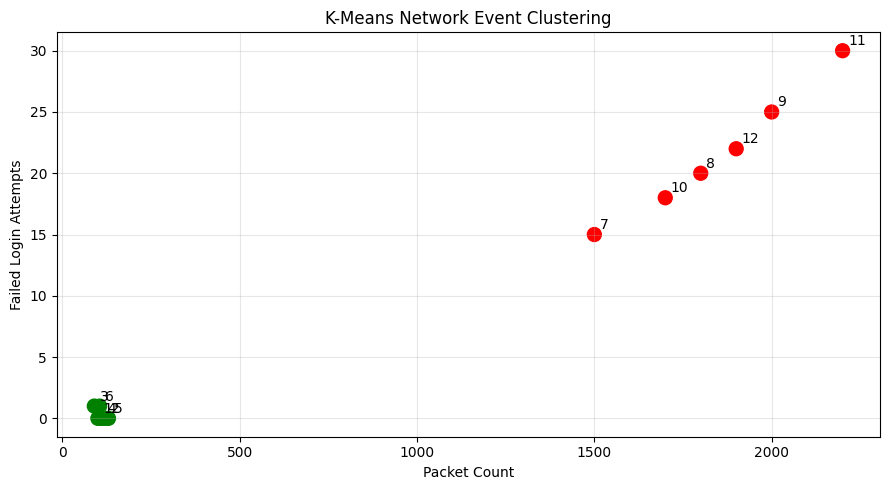

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 1: Create a sample network event dataset
data = {
    "Event_ID": range(1, 13),
    "Packet_Count": [
        100, 120, 90, 110, 130, 105,
        1500, 1800, 2000, 1700, 2200, 1900
    ],
    "Duration": [
        10, 12, 9, 11, 13, 10,
        2, 3, 1, 2, 1, 3
    ],
    "Failed_Logins": [
        0, 0, 1, 0, 0, 1,
        15, 20, 25, 18, 30, 22
    ]
}

df = pd.DataFrame(data)

# Step 2: Select features for clustering
features = ["Packet_Count", "Duration", "Failed_Logins"]
X = df[features]

# Step 3: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply K-means clustering
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# Step 5: Identify the abnormal cluster
# High packet count and failed logins with
# short duration indicate potentially abnormal events.
centers = scaler.inverse_transform(kmeans.cluster_centers_)

abnormal_cluster = max(
    range(2),
    key=lambda i: centers[i][0]
    + centers[i][2] * 20
    - centers[i][1] * 10
)

# Step 6: Assign readable labels
df["Category"] = df["Cluster"].apply(
    lambda cluster:
    "Abnormal" if cluster == abnormal_cluster
    else "Normal"
)

# Step 7: Display results
print("NETWORK EVENT CLASSIFICATION RESULTS")
print(df.to_string(index=False))

print("\nCluster Centers (original units):")
for i, center in enumerate(centers):
    print(
        f"Cluster {i}: "
        f"Packets={center[0]:.1f}, "
        f"Duration={center[1]:.1f}, "
        f"Failed Logins={center[2]:.1f}"
    )

print("\nCategory Summary:")
print(df["Category"].value_counts())

# Step 8: Visualize the clusters
colors = df["Category"].map({
    "Normal": "green",
    "Abnormal": "red"
})

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Packet_Count"],
    df["Failed_Logins"],
    c=colors,
    s=100
)

for _, row in df.iterrows():
    plt.annotate(
        str(row["Event_ID"]),
        (row["Packet_Count"], row["Failed_Logins"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Packet Count")
plt.ylabel("Failed Login Attempts")
plt.title("K-Means Network Event Clustering")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
